In [1]:
import sys
!{sys.executable} -m pip install ultralytics opencv-python pyyaml --quiet

'c:\Users\Andrew\Documents\AI' is not recognized as an internal or external command,
operable program or batch file.


In [2]:
import torch
print(f"PyTorch: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

PyTorch: 2.7.1+cu118
CUDA available: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


In [3]:
# ── CHANGE THIS to where you extracted the Kaggle dataset ────────────────────
KAGGLE_DATASET_PATH = r"archive"

# This is where the final ready-to-train dataset will be created
OUTPUT_DATASET_PATH = "datasets"

In [4]:
import os
import xml.etree.ElementTree as ET
import shutil
from pathlib import Path

def convert_xml_to_yolo(xml_path, img_w, img_h):
    """Convert one Pascal VOC XML file to YOLO format lines."""
    tree = ET.parse(xml_path)
    root = tree.getroot()
    yolo_lines = []

    for obj in root.findall('object'):
        name = obj.find('name').text.strip().lower()
        bndbox = obj.find('bndbox')
        xmin = float(bndbox.find('xmin').text)
        ymin = float(bndbox.find('ymin').text)
        xmax = float(bndbox.find('xmax').text)
        ymax = float(bndbox.find('ymax').text)

        # Convert to YOLO format (normalized cx, cy, w, h)
        cx = ((xmin + xmax) / 2) / img_w
        cy = ((ymin + ymax) / 2) / img_h
        w  = (xmax - xmin) / img_w
        h  = (ymax - ymin) / img_h

        # Clamp to valid range
        cx, cy, w, h = [min(max(v, 0.001), 0.999) for v in [cx, cy, w, h]]
        yolo_lines.append(f"0 {cx:.6f} {cy:.6f} {w:.6f} {h:.6f}")  # class 0 = gun

    return yolo_lines

# ── Find all images and XML files ─────────────────────────────────────────────
kaggle_path = Path(KAGGLE_DATASET_PATH)
all_images  = list(kaggle_path.rglob("*.jpg")) + list(kaggle_path.rglob("*.png")) + list(kaggle_path.rglob("*.jpeg"))
all_xmls    = {x.stem: x for x in kaggle_path.rglob("*.xml")}

print(f"Found {len(all_images)} images and {len(all_xmls)} XML annotations")

# ── Create output folder structure ────────────────────────────────────────────
for split in ["train", "val"]:
    Path(f"{OUTPUT_DATASET_PATH}/images/{split}").mkdir(parents=True, exist_ok=True)
    Path(f"{OUTPUT_DATASET_PATH}/labels/{split}").mkdir(parents=True, exist_ok=True)

# ── Split 80% train / 20% val and convert ────────────────────────────────────
import cv2
import random
random.seed(42)

matched = [(img, all_xmls[img.stem]) for img in all_images if img.stem in all_xmls]
unmatched = [img for img in all_images if img.stem not in all_xmls]

print(f"Matched image+label pairs: {len(matched)}")
print(f"Images without labels (skipped): {len(unmatched)}")

random.shuffle(matched)
split_idx  = int(len(matched) * 0.8)
train_data = matched[:split_idx]
val_data   = matched[split_idx:]

def process_split(data, split_name):
    count = 0
    for img_path, xml_path in data:
        img = cv2.imread(str(img_path))
        if img is None:
            continue
        h, w = img.shape[:2]

        yolo_lines = convert_xml_to_yolo(xml_path, w, h)
        if not yolo_lines:
            continue

        # Copy image
        ext = img_path.suffix
        dest_img = Path(f"{OUTPUT_DATASET_PATH}/images/{split_name}/{img_path.name}")
        shutil.copy(img_path, dest_img)

        # Save label
        dest_lbl = Path(f"{OUTPUT_DATASET_PATH}/labels/{split_name}/{img_path.stem}.txt")
        with open(dest_lbl, 'w') as f:
            f.write('\n'.join(yolo_lines))

        count += 1
    print(f"✅ {split_name}: {count} images processed")

process_split(train_data, "train")
process_split(val_data,   "val")

Found 666 images and 0 XML annotations
Matched image+label pairs: 0
Images without labels (skipped): 666
✅ train: 0 images processed
✅ val: 0 images processed


In [5]:
from pathlib import Path

archive = Path("archive")

# Show full folder structure
for item in sorted(archive.rglob("*"))[:50]:
    print(item)

archive\Images
archive\Images\1.jpeg
archive\Images\10.jpeg
archive\Images\100.jpeg
archive\Images\101.jpeg
archive\Images\102.jpeg
archive\Images\103.jpeg
archive\Images\104.jpeg
archive\Images\105.jpeg
archive\Images\106.jpeg
archive\Images\107.jpeg
archive\Images\108.jpeg
archive\Images\109.jpeg
archive\Images\11.jpeg
archive\Images\110.jpeg
archive\Images\111.jpeg
archive\Images\112.jpeg
archive\Images\113.jpeg
archive\Images\114.jpeg
archive\Images\115.jpeg
archive\Images\116.jpeg
archive\Images\117.jpeg
archive\Images\118.jpeg
archive\Images\119.jpeg
archive\Images\12.jpeg
archive\Images\120.jpeg
archive\Images\121.jpeg
archive\Images\122.jpeg
archive\Images\123.jpeg
archive\Images\124.jpeg
archive\Images\125.jpeg
archive\Images\126.jpeg
archive\Images\127.jpeg
archive\Images\128.jpeg
archive\Images\129.jpeg
archive\Images\13.jpeg
archive\Images\130.jpeg
archive\Images\131.jpeg
archive\Images\132.jpeg
archive\Images\133.jpeg
archive\Images\134.jpeg
archive\Images\135.jpeg
archive

In [6]:
from pathlib import Path

archive = Path("archive")

# Show ALL non-image files
non_images = [f for f in archive.rglob("*") if f.is_file() and f.suffix.lower() not in ['.jpg', '.jpeg', '.png']]

if non_images:
    print(f"Found {len(non_images)} non-image files:")
    for f in non_images:
        print(f"  {f}")
else:
    print("❌ No annotation files found at all — only images exist")

# Also count total images
images = list(archive.rglob("*.jpeg")) + list(archive.rglob("*.jpg")) + list(archive.rglob("*.png"))
print(f"\nTotal images: {len(images)}")

Found 670 non-image files:
  archive\LICENSE
  archive\README.md
  archive\Labels\1.txt
  archive\Labels\10.txt
  archive\Labels\100.txt
  archive\Labels\101.txt
  archive\Labels\102.txt
  archive\Labels\103.txt
  archive\Labels\104.txt
  archive\Labels\105.txt
  archive\Labels\106.txt
  archive\Labels\107.txt
  archive\Labels\108.txt
  archive\Labels\109.txt
  archive\Labels\11.txt
  archive\Labels\110.txt
  archive\Labels\111.txt
  archive\Labels\112.txt
  archive\Labels\113.txt
  archive\Labels\114.txt
  archive\Labels\115.txt
  archive\Labels\116.txt
  archive\Labels\117.txt
  archive\Labels\118.txt
  archive\Labels\119.txt
  archive\Labels\12.txt
  archive\Labels\120.txt
  archive\Labels\121.txt
  archive\Labels\122.txt
  archive\Labels\123.txt
  archive\Labels\124.txt
  archive\Labels\125.txt
  archive\Labels\126.txt
  archive\Labels\127.txt
  archive\Labels\128.txt
  archive\Labels\129.txt
  archive\Labels\13.txt
  archive\Labels\130.txt
  archive\Labels\131.txt
  archive\Labels

In [7]:
from pathlib import Path

# Check what format the labels are in
for txt in sorted(Path("archive/Labels").glob("*.txt"))[:3]:
    print(f"=== {txt.name} ===")
    print(txt.read_text())
    print()

=== 1.txt ===
1
76 45 146 87


=== 10.txt ===
1
115 130 163 161


=== 100.txt ===
1
9 23 225 107




In [8]:
import cv2
import shutil
import random
from pathlib import Path

KAGGLE_DATASET_PATH = "archive"
OUTPUT_DATASET_PATH = "datasets"

img_dir = Path(KAGGLE_DATASET_PATH) / "Images"
lbl_dir = Path(KAGGLE_DATASET_PATH) / "Labels"

# ── Match images to labels ────────────────────────────────────────────────────
all_images = list(img_dir.glob("*.jpeg")) + list(img_dir.glob("*.jpg")) + list(img_dir.glob("*.png"))
matched = [(img, lbl_dir / (img.stem + ".txt")) for img in all_images if (lbl_dir / (img.stem + ".txt")).exists()]
unmatched = [img for img in all_images if not (lbl_dir / (img.stem + ".txt")).exists()]

print(f"Total images     : {len(all_images)}")
print(f"Matched pairs    : {len(matched)}")
print(f"Missing labels   : {len(unmatched)}")

# ── Create output folders ─────────────────────────────────────────────────────
for split in ["train", "val"]:
    Path(f"{OUTPUT_DATASET_PATH}/images/{split}").mkdir(parents=True, exist_ok=True)
    Path(f"{OUTPUT_DATASET_PATH}/labels/{split}").mkdir(parents=True, exist_ok=True)

# ── Split 80/20 ───────────────────────────────────────────────────────────────
random.seed(42)
random.shuffle(matched)
split_idx  = int(len(matched) * 0.8)
train_data = matched[:split_idx]
val_data   = matched[split_idx:]

def convert_and_copy(data, split_name):
    count = 0
    skipped = 0
    for img_path, lbl_path in data:
        # Read image to get dimensions
        img = cv2.imread(str(img_path))
        if img is None:
            skipped += 1
            continue
        img_h, img_w = img.shape[:2]

        # Convert labels
        yolo_lines = []

Total images     : 333
Matched pairs    : 333
Missing labels   : 0


In [9]:
import yaml
from pathlib import Path

data = {
    'path': 'datasets',
    'train': 'images/train',
    'val':   'images/val',
    'nc':    1,
    'names': ['gun']
}

with open('datasets/data.yaml', 'w') as f:
    yaml.dump(data, f, sort_keys=False)

print("✅ data.yaml created")
print(f"Train images: {len(list(Path('datasets/images/train').iterdir()))}")
print(f"Val images  : {len(list(Path('datasets/images/val').iterdir()))}")

✅ data.yaml created
Train images: 0
Val images  : 0


In [10]:
from pathlib import Path

archive = Path("archive")
img_dir = archive / "Images"
lbl_dir = archive / "Labels"

print(f"Images folder exists: {img_dir.exists()}")
print(f"Labels folder exists: {lbl_dir.exists()}")

all_images = list(img_dir.glob("*.jpeg")) + list(img_dir.glob("*.jpg")) + list(img_dir.glob("*.png"))
all_labels = list(lbl_dir.glob("*.txt"))

print(f"Images found: {len(all_images)}")
print(f"Labels found: {len(all_labels)}")

# Show first 3 image names and first 3 label names
print("\nFirst 3 images:")
for f in all_images[:3]:
    print(f"  {f.name}")

print("\nFirst 3 labels:")
for f in all_labels[:3]:
    print(f"  {f.name}")

# Check if stems match
img_stems = {f.stem for f in all_images}
lbl_stems = {f.stem for f in all_labels}
matched = img_stems & lbl_stems
print(f"\nMatched stems: {len(matched)}")
print(f"Sample matched: {list(matched)[:5]}")

Images folder exists: True
Labels folder exists: True
Images found: 333
Labels found: 333

First 3 images:
  1.jpeg
  10.jpeg
  100.jpeg

First 3 labels:
  1.txt
  10.txt
  100.txt

Matched stems: 333
Sample matched: ['249', '109', '189', '154', '180']


In [11]:
import cv2
import shutil
import random
from pathlib import Path

img_dir = Path("archive/Images")
lbl_dir = Path("archive/Labels")

all_images = list(img_dir.glob("*.jpeg")) + list(img_dir.glob("*.jpg")) + list(img_dir.glob("*.png"))
matched = [(img, lbl_dir / (img.stem + ".txt")) for img in all_images if (lbl_dir / (img.stem + ".txt")).exists()]

print(f"Matched pairs: {len(matched)}")

for split in ["train", "val"]:
    Path(f"datasets/images/{split}").mkdir(parents=True, exist_ok=True)
    Path(f"datasets/labels/{split}").mkdir(parents=True, exist_ok=True)

random.seed(42)
random.shuffle(matched)
split_idx  = int(len(matched) * 0.8)
train_data = matched[:split_idx]
val_data   = matched[split_idx:]

def convert_and_copy(data, split_name):
    count = 0
    skipped = 0
    for img_path, lbl_path in data:
        img = cv2.imread(str(img_path))
        if img is None:
            skipped += 1
            continue
        img_h, img_w = img.shape[:2]

        yolo_lines = []
        with open(lbl_path) as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) != 5:
                    continue
                cls, xmin, ymin, xmax, ymax = map(float, parts)
                cx = ((xmin + xmax) / 2) / img_w
                cy = ((ymin + ymax) / 2) / img_h
                w  = (xmax - xmin) / img_w
                h  = (ymax - ymin) / img_h
                cx, cy, w, h = [min(max(v, 0.001), 0.999) for v in [cx, cy, w, h]]
                yolo_lines.append(f"0 {cx:.6f} {cy:.6f} {w:.6f} {h:.6f}")

        if not yolo_lines:
            skipped += 1
            continue

        dest_img = Path(f"datasets/images/{split_name}/{img_path.name}")
        shutil.copy(img_path, dest_img)

        dest_lbl = Path(f"datasets/labels/{split_name}/{img_path.stem}.txt")
        with open(dest_lbl, 'w') as f:
            f.write('\n'.join(yolo_lines))

        count += 1

    print(f"✅ {split_name}: {count} images processed, {skipped} skipped")

convert_and_copy(train_data, "train")
convert_and_copy(val_data,   "val")

Matched pairs: 333
✅ train: 0 images processed, 266 skipped
✅ val: 0 images processed, 67 skipped


In [12]:
import cv2
from pathlib import Path

img_dir = Path("archive/Images")
images = list(img_dir.glob("*.jpeg"))[:5]

for img_path in images:
    img = cv2.imread(str(img_path))
    if img is None:
        print(f"❌ Failed to read: {img_path.name}")
        # Try with PIL instead
        from PIL import Image
        try:
            pil_img = Image.open(img_path)
            print(f"   PIL size: {pil_img.size}, mode: {pil_img.mode}")
        except Exception as e:
            print(f"   PIL also failed: {e}")
    else:
        print(f"✅ {img_path.name}: {img.shape}")

✅ 1.jpeg: (145, 347, 3)
✅ 10.jpeg: (300, 168, 3)
✅ 100.jpeg: (168, 300, 3)
✅ 101.jpeg: (168, 300, 3)
✅ 102.jpeg: (183, 275, 3)


In [13]:
import cv2
from pathlib import Path

img_dir = Path("archive/Images")
lbl_dir = Path("archive/Labels")

# Test on first 3 pairs
for img_path in list(img_dir.glob("*.jpeg"))[:3]:
    lbl_path = lbl_dir / (img_path.stem + ".txt")
    img = cv2.imread(str(img_path))
    img_h, img_w = img.shape[:2]
    
    print(f"\n=== {img_path.name} ({img_w}x{img_h}) ===")
    print(f"Label content: {lbl_path.read_text().strip()}")
    
    with open(lbl_path) as f:
        for line in f:
            parts = line.strip().split()
            print(f"Parts: {parts}, Length: {len(parts)}")


=== 1.jpeg (347x145) ===
Label content: 1
76 45 146 87
Parts: ['1'], Length: 1
Parts: ['76', '45', '146', '87'], Length: 4

=== 10.jpeg (168x300) ===
Label content: 1
115 130 163 161
Parts: ['1'], Length: 1
Parts: ['115', '130', '163', '161'], Length: 4

=== 100.jpeg (300x168) ===
Label content: 1
9 23 225 107
Parts: ['1'], Length: 1
Parts: ['9', '23', '225', '107'], Length: 4


In [14]:
import cv2
import shutil
import random
from pathlib import Path

img_dir = Path("archive/Images")
lbl_dir = Path("archive/Labels")

all_images = list(img_dir.glob("*.jpeg")) + list(img_dir.glob("*.jpg")) + list(img_dir.glob("*.png"))
matched = [(img, lbl_dir / (img.stem + ".txt")) for img in all_images if (lbl_dir / (img.stem + ".txt")).exists()]

print(f"Matched pairs: {len(matched)}")

for split in ["train", "val"]:
    Path(f"datasets/images/{split}").mkdir(parents=True, exist_ok=True)
    Path(f"datasets/labels/{split}").mkdir(parents=True, exist_ok=True)

random.seed(42)
random.shuffle(matched)
split_idx  = int(len(matched) * 0.8)
train_data = matched[:split_idx]
val_data   = matched[split_idx:]

def convert_and_copy(data, split_name):
    count = 0
    skipped = 0
    for img_path, lbl_path in data:
        img = cv2.imread(str(img_path))
        if img is None:
            skipped += 1
            continue
        img_h, img_w = img.shape[:2]

        # ── Read label: class on line 1, coords on line 2 ────────────────────
        with open(lbl_path) as f:
            lines = [l.strip() for l in f.readlines() if l.strip()]

        if len(lines) < 2:
            skipped += 1
            continue

        try:
            cls  = int(lines[0])
            xmin, ymin, xmax, ymax = map(float, lines[1].split())
        except ValueError:
            skipped += 1
            continue

        # ── Convert to YOLO normalized format ────────────────────────────────
        cx = ((xmin + xmax) / 2) / img_w
        cy = ((ymin + ymax) / 2)

Matched pairs: 333


In [15]:
import cv2
import shutil
from pathlib import Path

img_path = Path("archive/Images/1.jpeg")
lbl_path = Path("archive/Labels/1.txt")

img = cv2.imread(str(img_path))
img_h, img_w = img.shape[:2]
print(f"Image size: {img_w}x{img_h}")

with open(lbl_path) as f:
    lines = [l.strip() for l in f.readlines() if l.strip()]

print(f"Lines: {lines}")

cls = int(lines[0])
xmin, ymin, xmax, ymax = map(float, lines[1].split())

cx = ((xmin + xmax) / 2) / img_w
cy = ((ymin + ymax) / 2) / img_h
w  = (xmax - xmin) / img_w
h  = (ymax - ymin) / img_h
cx, cy, w, h = [min(max(v, 0.001), 0.999) for v in [cx, cy, w, h]]

print(f"YOLO line: 0 {cx:.6f} {cy:.6f} {w:.6f} {h:.6f}")

# Test copy
Path("datasets/images/train").mkdir(parents=True, exist_ok=True)
Path("datasets/labels/train").mkdir(parents=True, exist_ok=True)
shutil.copy(img_path, "datasets/images/train/1.jpeg")
with open("datasets/labels/train/1.txt", 'w') as f:
    f.write(f"0 {cx:.6f} {cy:.6f} {w:.6f} {h:.6f}\n")

print("✅ Single image test passed!")

Image size: 347x145
Lines: ['1', '76 45 146 87']
YOLO line: 0 0.319885 0.455172 0.201729 0.289655
✅ Single image test passed!


In [17]:
import cv2
import shutil
import random
from pathlib import Path

# ── Wipe and recreate folders cleanly ────────────────────────────────────────
if Path("datasets").exists():
    shutil.rmtree("datasets")

for split in ["train", "val"]:
    Path(f"datasets/images/{split}").mkdir(parents=True, exist_ok=True)
    Path(f"datasets/labels/{split}").mkdir(parents=True, exist_ok=True)

img_dir = Path("archive/Images")
lbl_dir = Path("archive/Labels")

all_images = list(img_dir.glob("*.jpeg")) + list(img_dir.glob("*.jpg")) + list(img_dir.glob("*.png"))
matched = [(img, lbl_dir / (img.stem + ".txt")) for img in all_images if (lbl_dir / (img.stem + ".txt")).exists()]

random.seed(42)
random.shuffle(matched)
split_idx  = int(len(matched) * 0.8)
train_data = matched[:split_idx]
val_data   = matched[split_idx:]

print(f"Matched pairs : {len(matched)}")
print(f"Train         : {len(train_data)}")
print(f"Val           : {len(val_data)}")

def convert_and_copy(data, split_name):
    count = 0
    skipped = 0
    for img_path, lbl_path in data:
        try:
            img = cv2.imread(str(img_path))
            if img is None:
                skipped += 1
                continue
            img_h, img_w = img.shape[:2]

            with open(lbl_path) as f:
                lines = [l.strip() for l in f.readlines() if l.strip()]
            if len(lines) < 2:
                skipped += 1
                continue

            cls = int(lines[0])
            xmin, ymin, xmax, ymax = map(float, lines[1].split())

            cx = ((xmin + xmax) / 2) / img_w
            cy = ((ymin + ymax) / 2) / img_h
            w  = (xmax - xmin) / img_w
            h  = (ymax - ymin) / img_h
            cx, cy, w, h = [min(max(v, 0.001), 0.999) for v in [cx, cy, w, h]]

            shutil.copy(img_path, f"datasets/images/{split_name}/{img_path.name}")
            with open(f"datasets/labels/{split_name}/{img_path.stem}.txt", 'w') as f:
                f.write(f"0 {cx:.6f} {cy:.6f} {w:.6f} {h:.6f}\n")
            count += 1

        except Exception as e:
            print(f"  ⚠️ Error on {img_path.name}: {e}")
            skipped += 1

    print(f"✅ {split_name}: {count} processed, {skipped} skipped")

convert_and_copy(train_data, "train")
convert_and_copy(val_data, "val")

print(f"\nFinal train images : {len(list(Path('datasets/images/train').iterdir()))}")
print(f"Final val images   : {len(list(Path('datasets/images/val').iterdir()))}")

Matched pairs : 333
Train         : 266
Val           : 67
✅ train: 266 processed, 0 skipped
✅ val: 67 processed, 0 skipped

Final train images : 266
Final val images   : 67


In [18]:
import yaml
from pathlib import Path

data = {
    'path': 'datasets',
    'train': 'images/train',
    'val':   'images/val',
    'nc':    1,
    'names': ['gun']
}

with open('datasets/data.yaml', 'w') as f:
    yaml.dump(data, f, sort_keys=False)

print("✅ data.yaml created")
print(f"Train images: {len(list(Path('datasets/images/train').iterdir()))}")
print(f"Val images  : {len(list(Path('datasets/images/val').iterdir()))}")

✅ data.yaml created
Train images: 266
Val images  : 67


In [19]:
import cv2
import numpy as np
from pathlib import Path

img_dir = Path("datasets/images/train")
lbl_dir = Path("datasets/labels/train")

original_imgs = [f for f in img_dir.glob("*.jpeg") if "_aug_" not in f.stem]

def parse_labels(lbl_path):
    with open(lbl_path) as f:
        return [list(map(float, l.strip().split())) for l in f if l.strip()]

def save_labels(lbl_path, labels):
    with open(lbl_path, 'w') as f:
        for row in labels:
            f.write(' '.join(map(str, row)) + '\n')

def flip_boxes(labels):
    return [[cls, 1.0 - cx, cy, w, h] for cls, cx, cy, w, h in labels]

count = 0
for img_path in original_imgs:
    lbl_path = lbl_dir / (img_path.stem + ".txt")
    if not lbl_path.exists():
        continue

    img = cv2.imread(str(img_path))
    if img is None:
        continue
    labels = parse_labels(lbl_path)

In [21]:
from ultralytics import YOLO

model = YOLO("yolo11s.pt")

model.train(
    data="datasets/data.yaml",
    epochs=150,
    patience=50,
    imgsz=640,
    batch=8,
    optimizer="SGD",
    lr0=0.01,
    lrf=0.01,
    warmup_epochs=3,
    weight_decay=0.0005,
    augment=True,
    mosaic=1.0,
    fliplr=0.5,
    hsv_h=0.015,
    hsv_s=0.7,
    hsv_v=0.4,
    pretrained=True,
    name="gun_detector"
)

New https://pypi.org/project/ultralytics/8.4.68 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.56  Python-3.12.10 torch-2.7.1+cu118 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=True, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=datasets/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=150, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x0000014061D59B80>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.0480

In [23]:
pip install pandas

  Using cached tzdata-2026.2-py2.py3-none-any.whl.metadata (1.4 kB)
   ---------------------------------------- 0.0/9.8 MB ? eta -:--:--
   ------ --------------------------------- 1.6/9.8 MB 10.5 MB/s eta 0:00:01
   ---------------- ----------------------- 3.9/9.8 MB 11.2 MB/s eta 0:00:01
   ----------------------------- ---------- 7.1/9.8 MB 12.1 MB/s eta 0:00:01
   ---------------------------------------  9.7/9.8 MB 12.6 MB/s eta 0:00:01
   ---------------------------------------- 9.8/9.8 MB 12.2 MB/s  0:00:00
Using cached tzdata-2026.2-py2.py3-none-any.whl (349 kB)

   ---------------------------------------- 0/2 [tzdata]
   ---------------------------------------- 0/2 [tzdata]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- 

In [24]:
import pandas as pd
from pathlib import Path

runs = sorted(Path("runs/detect").glob("gun_detector*"), key=lambda f: f.stat().st_mtime)
latest = [r for r in runs if (r / "results.csv").exists()][-1]
df = pd.read_csv(latest / "results.csv")
df.columns = df.columns.str.strip()
print(df[["epoch", "train/box_loss", "train/cls_loss", "metrics/mAP50(B)"]].to_string())

    epoch  train/box_loss  train/cls_loss  metrics/mAP50(B)
0       1         1.94041         5.85252           0.44742
1       2         1.75639         1.87210           0.67259
2       3         1.74067         2.23236           0.22758
3       4         1.78363         2.32836           0.44419
4       5         1.76522         2.01360           0.61541
5       6         1.67872         2.03261           0.57073
6       7         1.67326         1.74792           0.31035
7       8         1.68679         1.69102           0.62549
8       9         1.65474         1.70000           0.73963
9      10         1.59615         1.51917           0.59584
10     11         1.71640         1.58553           0.61933
11     12         1.64344         1.55895           0.62929
12     13         1.68689         1.61938           0.55778
13     14         1.61916         1.44098           0.62450
14     15         1.57039         1.38910           0.45283
15     16         1.58691         1.3644

Using: runs\detect\gun_detector-19\weights\best.pt

image 1/67 c:\Users\Andrew\Documents\AI ML\Python AI ML Class Capstone\Capstone\datasets\images\val\101.jpeg: 384x640 (no detections), 68.5ms
image 2/67 c:\Users\Andrew\Documents\AI ML\Python AI ML Class Capstone\Capstone\datasets\images\val\11.jpeg: 384x640 1 gun, 7.0ms
image 3/67 c:\Users\Andrew\Documents\AI ML\Python AI ML Class Capstone\Capstone\datasets\images\val\110.jpeg: 448x640 1 gun, 70.5ms
image 4/67 c:\Users\Andrew\Documents\AI ML\Python AI ML Class Capstone\Capstone\datasets\images\val\112.jpeg: 384x640 1 gun, 10.3ms
image 5/67 c:\Users\Andrew\Documents\AI ML\Python AI ML Class Capstone\Capstone\datasets\images\val\113.jpeg: 384x640 1 gun, 7.2ms
image 6/67 c:\Users\Andrew\Documents\AI ML\Python AI ML Class Capstone\Capstone\datasets\images\val\119.jpeg: 352x640 1 gun, 65.6ms
image 7/67 c:\Users\Andrew\Documents\AI ML\Python AI ML Class Capstone\Capstone\datasets\images\val\12.jpeg: 480x640 (no detections), 58.9ms
image 8/

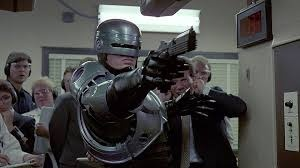

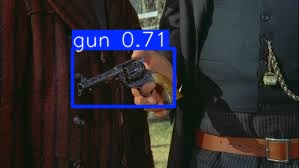

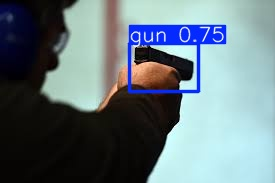

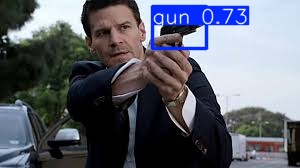

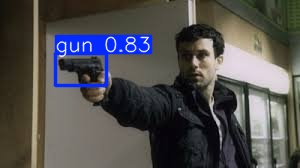

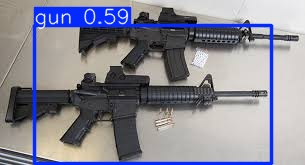

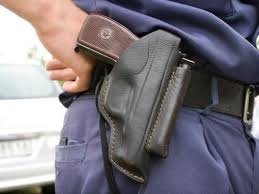

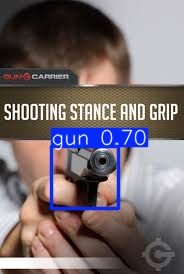

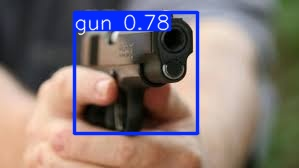

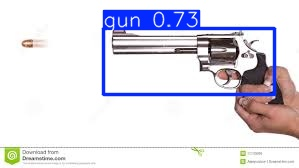

In [25]:
from ultralytics import YOLO
from pathlib import Path
from IPython.display import Image, display

# ── Find best weights ─────────────────────────────────────────────────────────
runs = sorted(Path("runs/detect").glob("gun_detector*"), key=lambda f: f.stat().st_mtime)
best_weights = runs[-1] / "weights" / "best.pt"
print(f"Using: {best_weights}")

model = YOLO(str(best_weights))

model.predict(
    source="datasets/images/val",
    save=True,
    name="gun_detector_predict",
    conf=0.5,
    iou=0.4,
    max_det=5,
    agnostic_nms=True,
)

results_dir = sorted(
    Path("runs/detect").glob("gun_detector_predict*"),
    key=lambda f: f.stat().st_mtime
)[-1]

for image_path in list(results_dir.glob("*.*"))[:10]:
    display(Image(filename=str(image_path), height=400))
    print('\n')